In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import LOB

In [2]:
import torch 

torch.cuda.is_available()

False

In [4]:
# !pip install torch
# !pip install cupy
# !pip install scikit-learn

In [3]:
import sys
#sys.path.insert(0, "/cygdrive/c/Users/Dell/OneDrive/Documents/TomDocuments/PythonProjects/PP/20261102/PatnaikPearson/PatnaikPearson")      # the folder containing the modules
sys.path.insert(0, "../../../PP/20261102/PatnaikPearson") 
import PatnaikPearson as pp

In [4]:
message_file = 'Data/AAPL_2026-03-04_34140000_57660000_message_10.csv' 
orderbook_file='Data/AAPL_2026-03-04_34140000_57660000_orderbook_10.csv'

In [15]:
use_price_diffs_z_scores = True
use_cum_size_z_scores = True
use_log_cum_size_z_scores = True
use_ob_imbalance = True
use_ob_imbalance_z_scores = True
use_ob_log_imbalance = True
use_ob_log_imbalance_z_scores = True
use_total_size_z_scores = True
use_log_total_size_z_scores = True
lookback = 1001

min_index = 30000
max_index = min_index + 20000

df_rep = LOB.create_representation_one(orderbook_file, 
                                       use_price_diffs_z_scores, 
                                       use_cum_size_z_scores, 
                                       use_log_cum_size_z_scores, 
                                       use_ob_imbalance, 
                                       use_ob_imbalance_z_scores, 
                                       use_ob_log_imbalance, 
                                       use_ob_log_imbalance_z_scores, 
                                       use_total_size_z_scores,
                                       use_log_total_size_z_scores,
                                       lookback, 
                                       min_index, 
                                       max_index)

In [16]:
print(df_rep.head(2))
print(df_rep.tail(2))

      AP2_minus_AP1_z  AP3_minus_AP1_z  AP4_minus_AP1_z  AP5_minus_AP1_z  \
1001        -0.404803        -0.618461        -0.682908        -0.801433   
1002        -0.403721        -0.616497        -0.680607        -0.798410   

      AP6_minus_AP1_z  AP7_minus_AP1_z  AP8_minus_AP1_z  AP9_minus_AP1_z  \
1001        -0.970474        -1.211737        -1.416700        -1.783054   
1002        -0.966149        -1.204881        -1.406949        -1.766059   

      AP10_minus_AP1_z  AP1_minus_BP1_z  ...  cum_BidSize_plus_AskSize_1_1_z  \
1001          0.853793         0.327459  ...                       -0.209756   
1002          0.850403         0.326626  ...                       -0.209252   

      cum_BidSize_plus_AskSize_1_2_z  cum_BidSize_plus_AskSize_1_3_z  \
1001                        0.380919                        0.521791   
1002                        0.379917                        0.520265   

      cum_BidSize_plus_AskSize_1_4_z  cum_BidSize_plus_AskSize_1_5_z  \
1001        

In [17]:
print(df_rep.shape)
#print(df_rep.columns)
num_nans = np.count_nonzero(np.isnan(df_rep))
print("num_nans = ", num_nans)

(18998, 138)
num_nans =  0


In [18]:
N = 500
i = N

X = df_rep.iloc[-N:].to_numpy()
print(X.shape)
num_nans = np.count_nonzero(np.isnan(X))
print("num_nans = ", num_nans)
pp.display_stats(X)
pp_dim_X = pp.calculate_PatnaikPearson_dim(X)
print("PP(X) = ", pp_dim_X)

(500, 138)
num_nans =  0
shape : (500, 138)
min : -6.68336758250183
max : 11.388885932200859
sum : 13703.995222718668
mean : 0.19860862641621257
std : 1.0223427828373148
** calculate_nu_cpu ** running on CPU
PP(X) =  16.919153422053938


In [25]:
stride = 50
N = 500
i_vals = []
pp_dim_X_over_dim_X_vals = []


for i in np.arange(N, df_rep.shape[0], stride):
    i_vals.append(i)
    X = df_rep.iloc[i - N : i].to_numpy()
    pp_dim_X = pp.calculate_PatnaikPearson_dim(X)
    dim_X = X.shape[1]
    pp_dim_X_over_dim_X_vals.append(pp_dim_X / dim_X)
    print(i, pp_dim_X)

** calculate_nu_cpu ** running on CPU
500 20.156048934189542
** calculate_nu_cpu ** running on CPU
550 19.44683170697031
** calculate_nu_cpu ** running on CPU
600 18.479153824495135
** calculate_nu_cpu ** running on CPU
650 17.77324847050061
** calculate_nu_cpu ** running on CPU
700 17.16458518963303
** calculate_nu_cpu ** running on CPU
750 15.270942257157461
** calculate_nu_cpu ** running on CPU
800 15.36030868494576
** calculate_nu_cpu ** running on CPU
850 15.63835812876221
** calculate_nu_cpu ** running on CPU
900 15.846713912829506
** calculate_nu_cpu ** running on CPU
950 15.785648444917598
** calculate_nu_cpu ** running on CPU
1000 16.274248852959076
** calculate_nu_cpu ** running on CPU
1050 16.62518766378702
** calculate_nu_cpu ** running on CPU
1100 16.756501825109932
** calculate_nu_cpu ** running on CPU
1150 16.37399849919374
** calculate_nu_cpu ** running on CPU
1200 16.085090487845534
** calculate_nu_cpu ** running on CPU
1250 17.692268030930613
** calculate_nu_cpu ** ru

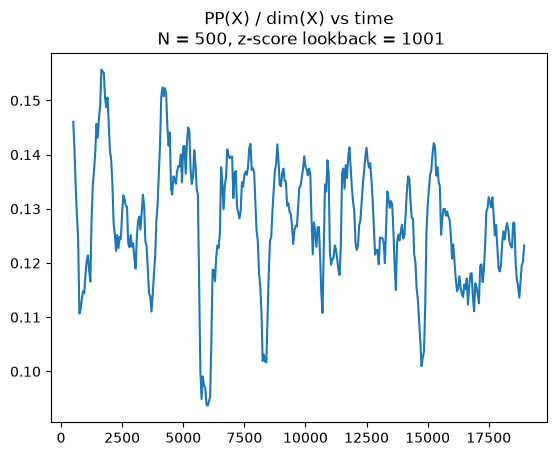

In [26]:
plt.plot(i_vals, pp_dim_X_over_dim_X_vals)
plt.title("PP(X) / dim(X) vs time" + "\n N = " + str(N) + ", z-score lookback = " + str(lookback))
plt.show()

### SPARE

In [23]:
min_index = 30000
max_index = 40000
df_ob = LOB.read_and_format_orderbook(orderbook_file, min_index, max_index)

In [30]:
lookback = 501

df_price_diffs = LOB.generate_orderbook_price_diffs(df_ob)
df_price_diffs_z_scores = LOB.expw_zscore(df_price_diffs, lookback)

In [32]:
print(df_price_diffs_z_scores.shape)
print(df_price_diffs_z_scores.head(2))
num_nans = np.count_nonzero(np.isnan(df_price_diffs))
print("df_price_diffs : num_nans = ", num_nans)
num_nans = np.count_nonzero(np.isnan(df_price_diffs_z_scores))
print("df_price_diffs_z_scores : num_nans = ", num_nans)

(9498, 38)
     AP2_minus_AP1_z  AP3_minus_AP1_z  AP4_minus_AP1_z  AP5_minus_AP1_z  \
501         2.890342         3.155588         2.637256         3.155989   
502         2.772147         3.005954         2.544716         3.006303   

     AP6_minus_AP1_z  AP7_minus_AP1_z  AP8_minus_AP1_z  AP9_minus_AP1_z  \
501         2.095902         1.349825         0.415825         0.436780   
502         2.045222         1.332473         0.413588         0.434395   

     AP10_minus_AP1_z  AP1_minus_BP1_z  ...  BP1_minus_AP1_z  BP2_minus_AP1_z  \
501          0.077918         1.390283  ...        -1.390283        -0.607178   
502          0.077558        -0.041607  ...         0.041607        -0.398230   

     BP3_minus_AP1_z  BP4_minus_AP1_z  BP5_minus_AP1_z  BP6_minus_AP1_z  \
501        -0.279250        -0.243451        -0.161217         0.093285   
502        -0.069021         0.645718         0.292129         0.497605   

     BP7_minus_AP1_z  BP8_minus_AP1_z  BP9_minus_AP1_z  BP10_minus_

In [34]:
df_ob_cum_size, df_ob_log_cum_size, df_ob_imbalance, df_ob_log_imbalance = LOB.generate_orderbook_cum_size_log_cum_size(df_ob)
            
df_ob_cum_size_z_scores = LOB.expw_zscore(df_ob_cum_size, lookback)
df_ob_log_cum_size_z_scores = LOB.expw_zscore(df_ob_log_cum_size, lookback)
df_ob_imbalance_z_scores = LOB.expw_zscore(df_ob_imbalance, lookback)
df_ob_log_imbalance_z_scores = LOB.expw_zscore(df_ob_log_imbalance, lookback)

In [35]:
num_nans = np.count_nonzero(np.isnan(df_ob_cum_size_z_scores))
print("df_ob_cum_size_z_scores : num_nans = ", num_nans)
num_nans = np.count_nonzero(np.isnan(df_ob_log_cum_size_z_scores))
print("df_ob_log_cum_size_z_scores : num_nans = ", num_nans)
num_nans = np.count_nonzero(np.isnan(df_ob_imbalance_z_scores))
print("df_ob_imbalance_z_scores : num_nans = ", num_nans)
num_nans = np.count_nonzero(np.isnan(df_ob_log_imbalance_z_scores))
print("df_ob_log_imbalance_z_scores : num_nans = ", num_nans)

df_ob_cum_size_z_scores : num_nans =  0
df_ob_log_cum_size_z_scores : num_nans =  0
df_ob_imbalance_z_scores : num_nans =  0
df_ob_log_imbalance_z_scores : num_nans =  0


In [47]:
df_representation_one = pd.DataFrame() # empty dataframe
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)
print("df_representation_one.size = ", df_representation_one.size)

df_representation_one = df_representation_one.join(df_price_diffs_z_scores)
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

df_representation_one = df_representation_one.join(df_ob_cum_size_z_scores)
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

df_representation_one = df_representation_one.join(df_ob_log_cum_size_z_scores)
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

df_representation_one = df_representation_one.join(df_ob_imbalance[lookback:])
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

df_representation_one = df_representation_one.join(df_ob_imbalance_z_scores)  
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

#df_representation_one = pd.concat([df_representation_one, df_ob_log_imbalance[lookback:]], axis = 1)
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

#df_representation_one = pd.concat([df_representation_one, df_ob_log_imbalance_z_scores], axis = 1)
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 0)
df_representation_one.size =  0
df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 38)
df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 58)
df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 78)
df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 88)
df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 98)
df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 98)
df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 98)


In [45]:
num_nans = np.count_nonzero(np.isnan(df_representation_one))
print("df_representation_one : num_nans = ", num_nans)
print("df_representation_one.shape = ", df_representation_one.shape)

xx = df_ob_log_imbalance[lookback:]
num_nans = np.count_nonzero(np.isnan(xx))
print("xx : num_nans = ", num_nans)
print("xx.shape = ", xx.shape)

yy = pd.concat([df_representation_one, xx], axis = 1)
num_nans = np.count_nonzero(np.isnan(yy))
print("yy : num_nans = ", num_nans)



#df_representation_one = pd.concat([df_representation_one, df_ob_log_imbalance[lookback:]], axis = 1)

df_representation_one : num_nans =  0
df_representation_one.shape =  (0, 98)
xx : num_nans =  0
xx.shape =  (9498, 10)
yy : num_nans =  930804
